In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns 

In [2]:
df = pd.read_csv(r"C:\Users\pc\Desktop\churn_analysis\customer_churn_dataset-testing-master.csv")
df.head()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,1,22,Female,25,14,4,27,Basic,Monthly,598,9,1
1,2,41,Female,28,28,7,13,Standard,Monthly,584,20,0
2,3,47,Male,27,10,2,29,Premium,Annual,757,21,0
3,4,35,Male,9,12,5,17,Premium,Quarterly,232,18,0
4,5,53,Female,58,24,9,2,Standard,Annual,533,18,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64374 entries, 0 to 64373
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   CustomerID         64374 non-null  int64 
 1   Age                64374 non-null  int64 
 2   Gender             64374 non-null  object
 3   Tenure             64374 non-null  int64 
 4   Usage Frequency    64374 non-null  int64 
 5   Support Calls      64374 non-null  int64 
 6   Payment Delay      64374 non-null  int64 
 7   Subscription Type  64374 non-null  object
 8   Contract Length    64374 non-null  object
 9   Total Spend        64374 non-null  int64 
 10  Last Interaction   64374 non-null  int64 
 11  Churn              64374 non-null  int64 
dtypes: int64(9), object(3)
memory usage: 5.9+ MB


In [4]:
df.columns = df.columns.str.strip()

In [5]:
df["Churn"] = df["Churn"].replace("", "0").astype(float)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64374 entries, 0 to 64373
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         64374 non-null  int64  
 1   Age                64374 non-null  int64  
 2   Gender             64374 non-null  object 
 3   Tenure             64374 non-null  int64  
 4   Usage Frequency    64374 non-null  int64  
 5   Support Calls      64374 non-null  int64  
 6   Payment Delay      64374 non-null  int64  
 7   Subscription Type  64374 non-null  object 
 8   Contract Length    64374 non-null  object 
 9   Total Spend        64374 non-null  int64  
 10  Last Interaction   64374 non-null  int64  
 11  Churn              64374 non-null  float64
dtypes: float64(1), int64(8), object(3)
memory usage: 5.9+ MB


In [7]:
df["Churn"] = df["Churn"].replace("", "0").astype(int)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64374 entries, 0 to 64373
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   CustomerID         64374 non-null  int64 
 1   Age                64374 non-null  int64 
 2   Gender             64374 non-null  object
 3   Tenure             64374 non-null  int64 
 4   Usage Frequency    64374 non-null  int64 
 5   Support Calls      64374 non-null  int64 
 6   Payment Delay      64374 non-null  int64 
 7   Subscription Type  64374 non-null  object
 8   Contract Length    64374 non-null  object
 9   Total Spend        64374 non-null  int64 
 10  Last Interaction   64374 non-null  int64 
 11  Churn              64374 non-null  int32 
dtypes: int32(1), int64(8), object(3)
memory usage: 5.6+ MB


In [9]:
df.isnull().sum()

CustomerID           0
Age                  0
Gender               0
Tenure               0
Usage Frequency      0
Support Calls        0
Payment Delay        0
Subscription Type    0
Contract Length      0
Total Spend          0
Last Interaction     0
Churn                0
dtype: int64

In [10]:
df.describe()

,CustomerID,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Churn
count,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000,64374.000000
mean,32187.500000,41.970982,31.994827,15.080234,5.400690,17.133952,541.023379,15.498850,0.473685
std,18583.317451,13.924911,17.098234,8.816470,3.114005,8.852211,260.874809,8.638436,0.499311
min,1.000000,18.000000,1.000000,1.000000,0.000000,0.000000,100.000000,1.000000,0.000000
25%,16094.250000,30.000000,18.000000,7.000000,3.000000,10.000000,313.000000,8.000000,0.000000
50%,32187.500000,42.000000,33.000000,15.000000,6.000000,19.000000,534.000000,15.000000,0.000000
75%,48280.750000,54.000000,47.000000,23.000000,8.000000,25.000000,768.000000,23.000000,1.000000
max,64374.000000,65.000000,60.000000,30.000000,10.000000,30.000000,1000.000000,30.000000,1.000000


In [11]:
df.duplicated().sum()

0

In [12]:
def conv(value):
    if value == 1:
        return "yes"
    else:
        return "no"
df["Churn"] = df["Churn"].apply(conv)

In [13]:
df.head()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,1,22,Female,25,14,4,27,Basic,Monthly,598,9,yes
1,2,41,Female,28,28,7,13,Standard,Monthly,584,20,no
2,3,47,Male,27,10,2,29,Premium,Annual,757,21,no
3,4,35,Male,9,12,5,17,Premium,Quarterly,232,18,no
4,5,53,Female,58,24,9,2,Standard,Annual,533,18,no


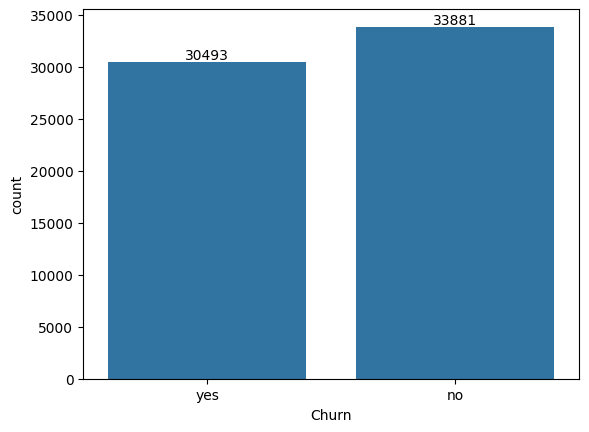

In [14]:
ax = sns.countplot(x ='Churn', data = df)
ax.bar_label(ax.containers[0])
plt.show()

In [15]:
gb = df.groupby("Churn").agg({'Churn': "count"})
print(gb)

       Churn
Churn       
no     33881
yes    30493


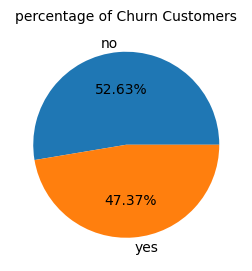

In [16]:
plt.figure(figsize =(3,4))
plt.title('percentage of Churn Customers', fontsize = 10)
plt.pie(gb['Churn'], labels = gb.index, autopct ='%1.2f%%')
plt.show()

#from the given pi chart we can conclude that 47.37% of our customers have churned out
#now let's explore reasonn behind this 

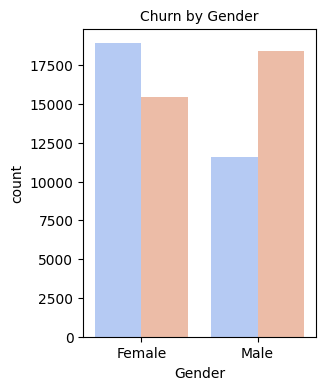

In [17]:
plt.figure(figsize = (3,4))
plt.title('Churn by Gender', fontsize = 10)
ax = sns.countplot(x='Gender', data=df, hue='Churn', palette='coolwarm', legend=False)
plt.show()

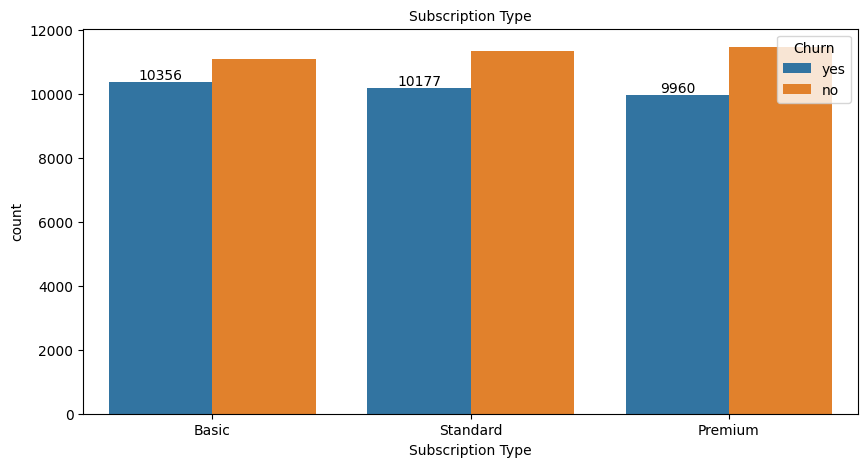

In [18]:
plt.figure(figsize = (10,5))
plt.title('Subscription Type', fontsize = 10)
ax = sns.countplot(x='Subscription Type', data=df, hue='Churn')
ax.bar_label(ax.containers[0])
plt.show()

<Figure size 1000x500 with 0 Axes>

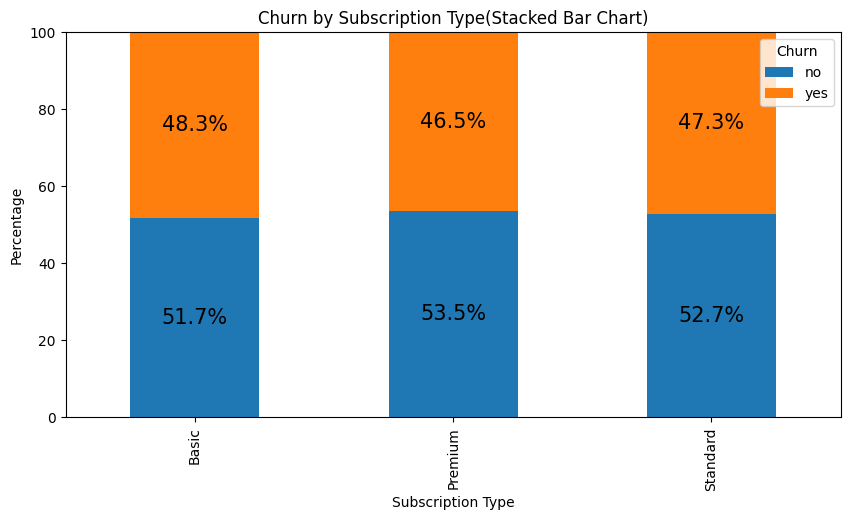

In [19]:
# Step 1: Count occurrences of each Churn category per Tenure
df_grouped = df.groupby(["Subscription Type", "Churn"]).size().unstack(fill_value=0)

# Step 2: Convert to percentage
df_percent = df_grouped.div(df_grouped.sum(axis=1), axis=0) * 100

# Step 3: Plot Stacked Bar Chart
plt.figure(figsize=(10, 5))
ax = df_percent.plot(kind="bar", stacked=True, figsize=(10, 5))

# Step 4: Add percentage labels
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", label_type="center", fontsize=15, color="black")

# Customize plot
plt.title('Churn by Subscription Type(Stacked Bar Chart)', fontsize=12)
plt.ylabel("Percentage")
plt.xlabel("Subscription Type")
plt.legend(title="Churn")
plt.ylim(0, 100)  # Y-axis represents 100% scale

# Show plot
plt.show()

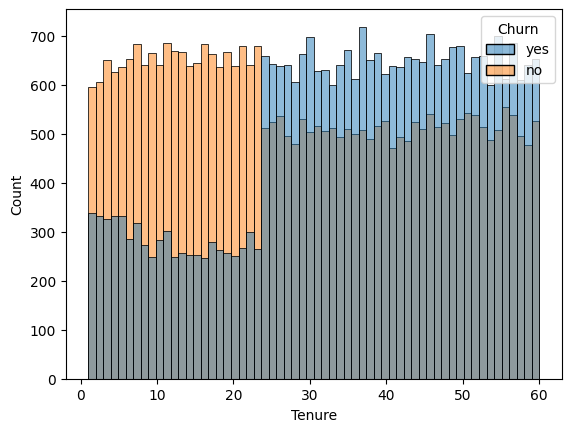

<Figure size 2000x1000 with 0 Axes>

In [20]:
ax = sns.histplot(x='Tenure', data = df, bins =60, hue= 'Churn')
#ax.bar_label(ax.containers[0])
plt.figure(figsize=(20,10))
plt.show()

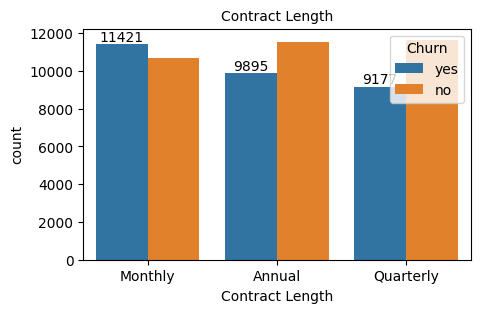

In [21]:
plt.figure(figsize = (5,3))
plt.title('Contract Length', fontsize = 10)
ax = sns.countplot(x='Contract Length', data=df, hue='Churn')
ax.bar_label(ax.containers[0])
plt.show()

In [22]:
df.columns.values

array(['CustomerID', 'Age', 'Gender', 'Tenure', 'Usage Frequency',
       'Support Calls', 'Payment Delay', 'Subscription Type',
       'Contract Length', 'Total Spend', 'Last Interaction', 'Churn'],
      dtype=object)

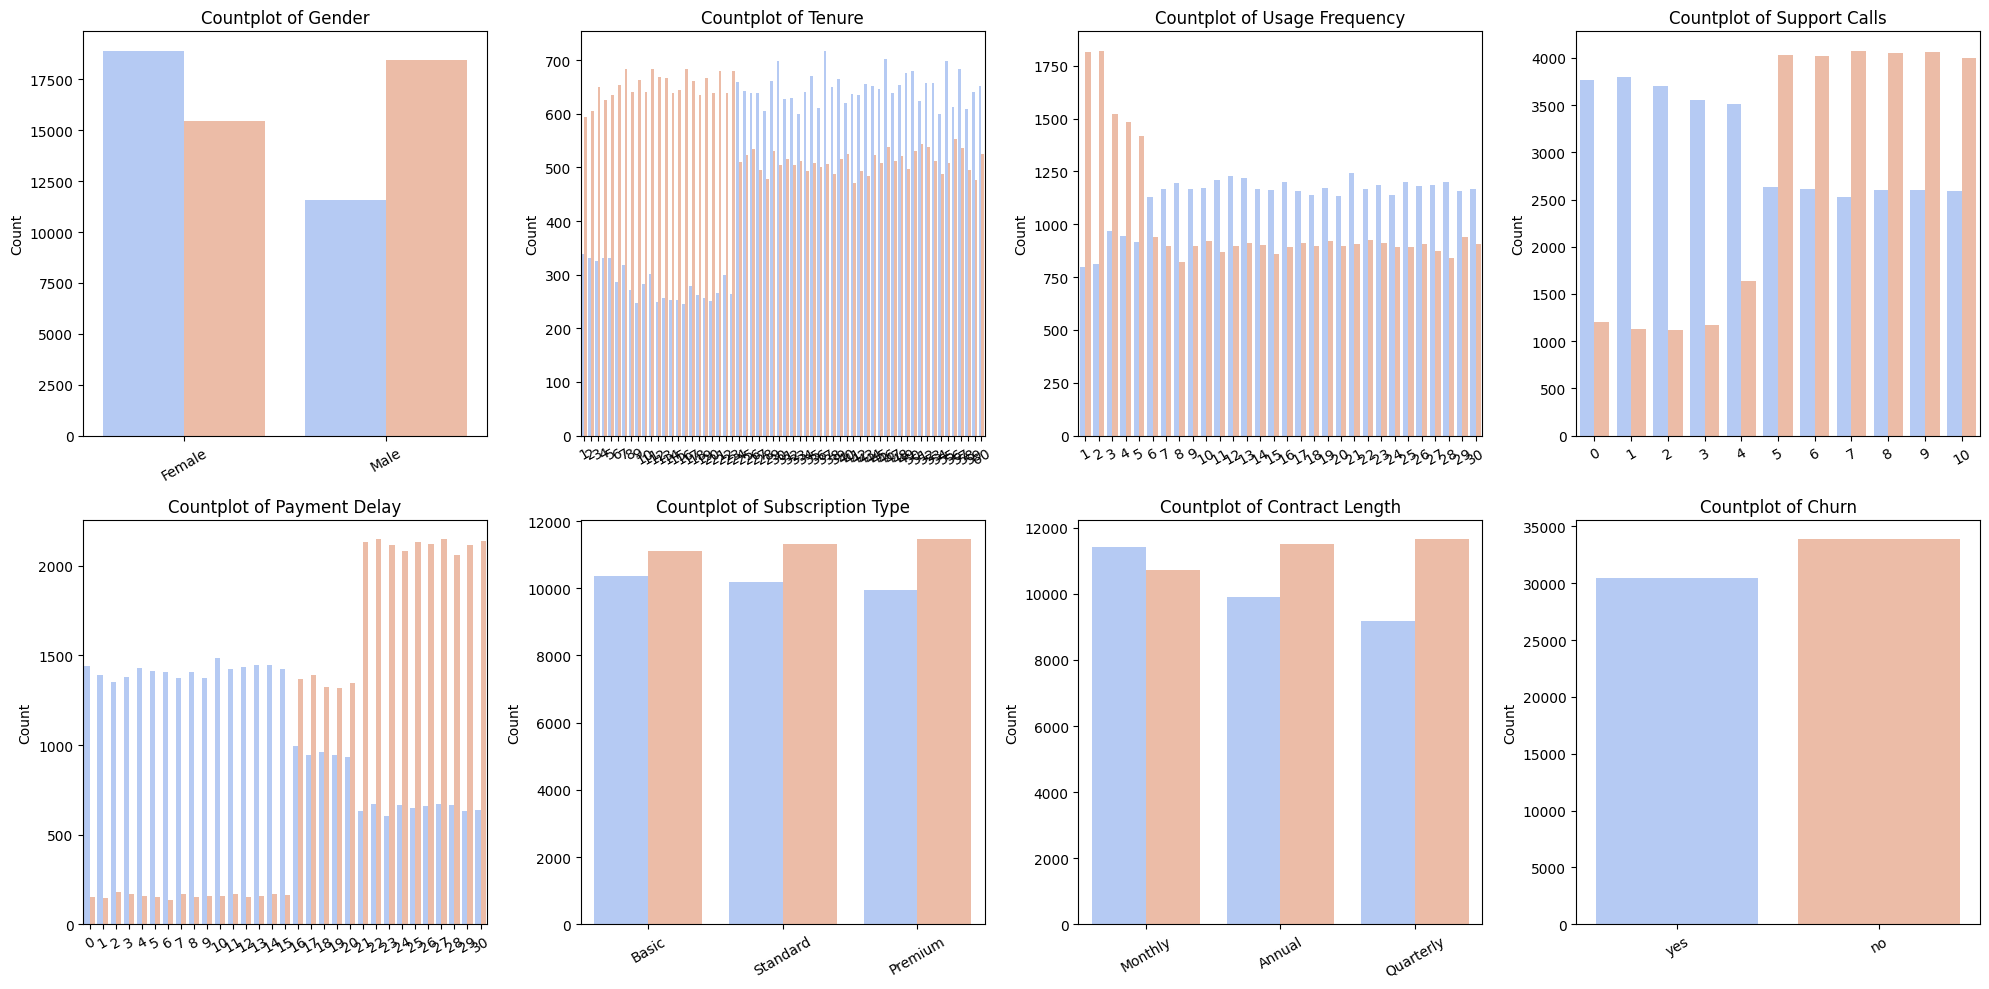

In [26]:
# Define columns to visualize (only categorical)
columns_to_plot = ['Gender', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 
                   'Subscription Type', 'Contract Length', 'Churn']

# Set figure size
fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(20, 10))  # 2 rows, 4 columns

# Flatten axes array for easy iteration
axes = axes.flatten()

# Loop through each column and create a countplot
for i, col in enumerate(columns_to_plot):
    sns.countplot(x=col, hue= df['Churn'], data=df, ax=axes[i], palette='coolwarm', legend=False)
    axes[i].set_title(f'Countplot of {col}', fontsize=12)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Count")
    axes[i].tick_params(axis='x', rotation=30)  # Rotate labels for better visibility

# Adjust layout
plt.tight_layout()
plt.show()


#The subplots provide insights into customer distribution across different attributes, categorized by churn. Key observations include:

Gender & Churn: Male and female distributions appear balanced, with a slightly higher churn tendency in one group.
Tenure & Churn: Customers with shorter tenures show a higher churn rate.
Usage & Payment Delay: Higher usage frequency and payment delays seem to correlate with churn patterns.
Subscription & Contract Length: Premium and longer-term contract users have lower churn rates compared to shorter contracts.